# TP3 · Clasificación de etapas de adopción de IA

**Pregunta:** ¿Se puede predecir la etapa de adopción (`none`, `pilot`, `partial`, `full`) usando características de contexto de la empresa y del período?

`ai_adoption_stage` se deriva por intervalos de `ai_adoption_rate`; por eso se excluyen ambas variables derivadas (`ai_adoption_rate` y `years_using_ai`) y se particiona por empresa. Se informa el desbalance de clases, se comparan cuatro clasificadores y se reservan empresas completas para la prueba. El clustering es complementario: se ajusta sin etiquetas en entrenamiento y luego se compara con las clases reales en prueba.

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, accuracy_score, precision_score, recall_score,
    silhouette_score, davies_bouldin_score,
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

SEMILLA = 2026
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR_BASE, COLOR_LINEA = "#2b5c8f", "#d95f02"

def encontrar_proyecto():
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if base.name == "proyecto_equipo" and (base / "notebooks").is_dir():
            return base
        if (base / "proyecto_equipo" / "notebooks").is_dir():
            return base / "proyecto_equipo"
    raise FileNotFoundError("No se encontró proyecto_equipo/notebooks")

PROYECTO = encontrar_proyecto()
RUTA_PARQUET = PROYECTO / "datos" / "derivados" / "ai_company_adoption_limpio.parquet"
if not RUTA_PARQUET.exists():
    raise FileNotFoundError("Ejecutá primero 02_limpieza_ai.ipynb para generar el Parquet limpio")
SALIDAS = PROYECTO / "salidas"
SALIDAS.mkdir(parents=True, exist_ok=True)
df = pd.read_parquet(RUTA_PARQUET)
assert df.shape == (150_000, 43), f"Dimensiones inesperadas: {df.shape}"
print(f"Dataset: {len(df):,} filas | {df['company_id'].nunique():,} empresas | {RUTA_PARQUET}")

Dataset: 150,000 filas | 10,000 empresas | /Users/agus/Documents/Codex/2026-10-05/https-github-com-taniagorosito-aa-2026/aa-2026-entorno/proyecto_equipo/datos/derivados/ai_company_adoption_limpio.parquet


## Marco experimental

La regresión logística multinomial es la referencia lineal. El árbol evalúa reglas no lineales interpretables; Gaussian Naive Bayes usa un supuesto probabilístico distinto; Random Forest prueba un ensamble de árboles. Las clases menos frecuentes reciben mayor peso en los modelos que admiten `class_weight`. Se reportan Accuracy junto con precision, recall y F1 macro/ponderado para no ocultar errores de clases minoritarias.

In [2]:
target_col = "ai_adoption_stage"
orden_etapas = ["none", "pilot", "partial", "full"]
y = df[target_col].astype("category").cat.reorder_categories(orden_etapas, ordered=True)

# Objetivo y predictores. La etiqueta se deriva de ai_adoption_rate, por eso se excluye
# tanto la tasa como years_using_ai y las métricas contemporáneas de impacto.
cols_cat = ["country", "industry"]
cols_log = ["num_employees", "annual_revenue_usd_millions"]
cols_std = ["company_age", "survey_year", "num_ai_tools_used", "ai_training_hours"]
predictores = cols_cat + cols_log + cols_std
X = df[predictores].copy()
grupos = df["company_id"].astype("string")

# Partición 80/20 que mantiene juntas las filas por empresa y aproxima estratificación por clase.
partidor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
train_idx, test_idx = next(partidor.split(X, y, groups=grupos))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
grupos_train, grupos_test = grupos.iloc[train_idx], grupos.iloc[test_idx]
assert set(grupos_train).isdisjoint(set(grupos_test))

frecuencias = []
for nombre, etiquetas in [("Total", y), ("Entrenamiento", y_train), ("Prueba", y_test)]:
    v = etiquetas.value_counts(normalize=True).reindex(orden_etapas).fillna(0)
    frecuencias.append(pd.DataFrame({"Conjunto": nombre, "Clase": orden_etapas, "Porcentaje (%)": (100*v).round(2).values}))
distribucion = pd.concat(frecuencias, ignore_index=True)
display(distribucion.pivot(index="Clase", columns="Conjunto", values="Porcentaje (%)"))
print(f"Entrenamiento: {len(X_train):,} filas / {grupos_train.nunique():,} empresas")
print(f"Prueba: {len(X_test):,} filas / {grupos_test.nunique():,} empresas; empresas compartidas: 0")

Conjunto,Entrenamiento,Prueba,Total
Clase,,,
full,1.12,1.12,1.12
none,3.46,3.47,3.47
partial,52.54,52.51,52.53
pilot,42.87,42.90,42.88


Entrenamiento: 119,996 filas / 8,000 empresas
Prueba: 30,004 filas / 2,000 empresas; empresas compartidas: 0


In [3]:
def crear_preprocesador():
    prep_log = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("escalar", StandardScaler()),
    ])
    prep_std = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    prep_cat = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("log", prep_log, cols_log),
        ("std", prep_std, cols_std),
        ("cat", prep_cat, cols_cat),
    ], remainder="drop")

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Logistic Regression es la referencia lineal y pondera las clases menos frecuentes.
pipe_lr = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", LogisticRegression(max_iter=500, class_weight="balanced", random_state=SEMILLA)),
])
# Árbol acotado y hojas grandes para reducir varianza y evitar hojas con pocos casos.
pipe_dt = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, class_weight="balanced", random_state=SEMILLA)),
])
# GaussianNB aporta una referencia probabilística con supuestos distintos.
pipe_nb = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", GaussianNB()),
])
# Random Forest evalúa si un ensamble de árboles mejora los modelos individuales.
pipe_rf = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", RandomForestClassifier(
        n_estimators=100, max_depth=10, min_samples_leaf=20,
        class_weight="balanced", random_state=SEMILLA, n_jobs=2,
    )),
])
modelos_clasif = {
    "Regresión logística": pipe_lr,
    "Árbol de decisión": pipe_dt,
    "Naive Bayes": pipe_nb,
    "Random Forest (ensamble)": pipe_rf,
}
print("Cuatro clasificadores inicializados; la regresión logística se usa como referencia.")

Cuatro clasificadores inicializados; la regresión logística se usa como referencia.


In [5]:
predicciones_train, predicciones_test = {}, {}
for nombre, modelo in modelos_clasif.items():
    modelo.fit(X_train, y_train)
    predicciones_train[nombre] = modelo.predict(X_train)
    predicciones_test[nombre] = modelo.predict(X_test)
    print(f"Entrenado y evaluado: {nombre}")

Entrenado y evaluado: Regresión logística
Entrenado y evaluado: Árbol de decisión
Entrenado y evaluado: Naive Bayes
Entrenado y evaluado: Random Forest (ensamble)


In [6]:
filas_metricas = []
for nombre in modelos_clasif:
    y_pred_tr, y_pred_te = predicciones_train[nombre], predicciones_test[nombre]
    filas_metricas.append({
        "Modelo": nombre,
        "Accuracy (Train)": round(accuracy_score(y_train, y_pred_tr), 3),
        "Accuracy (Test)": round(accuracy_score(y_test, y_pred_te), 3),
        "Precision macro (Train)": round(precision_score(y_train, y_pred_tr, average="macro", zero_division=0), 3),
        "Precision macro (Test)": round(precision_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
        "Recall macro (Train)": round(recall_score(y_train, y_pred_tr, average="macro", zero_division=0), 3),
        "Recall macro (Test)": round(recall_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
        "F1 macro (Train)": round(f1_score(y_train, y_pred_tr, average="macro", zero_division=0), 3),
        "F1 macro (Test)": round(f1_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
        "F1 ponderado (Train)": round(f1_score(y_train, y_pred_tr, average="weighted", zero_division=0), 3),
        "F1 ponderado (Test)": round(f1_score(y_test, y_pred_te, average="weighted", zero_division=0), 3),
        "Brecha F1 macro": round(f1_score(y_train, y_pred_tr, average="macro", zero_division=0) - f1_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
    })
df_comparativa_tp3 = pd.DataFrame(filas_metricas)
display(df_comparativa_tp3)
df_comparativa_tp3.to_csv(SALIDAS / "tabla_comparativa_clasificacion_tp3.csv", index=False)

# El criterio principal es F1 macro porque da igual peso a las cuatro clases.
mejor_clasificador = df_comparativa_tp3.sort_values("F1 macro (Test)", ascending=False).iloc[0]["Modelo"]
print(f"Mejor F1 macro de prueba: {mejor_clasificador}")

,Modelo,Accuracy (Train),Accuracy (Test),Precision macro (Train),Precision macro (Test),Recall macro (Train),Recall macro (Test),F1 macro (Train),F1 macro (Test),F1 ponderado (Train),F1 ponderado (Test),Brecha F1 macro
0,Regresión logística,0.628,0.633,0.465,0.467,0.760,0.759,0.491,0.495,0.657,0.660,-0.004
1,Árbol de decisión,0.617,0.618,0.465,0.462,0.765,0.742,0.487,0.484,0.647,0.648,0.003
2,Naive Bayes,0.541,0.533,0.394,0.382,0.630,0.584,0.408,0.394,0.566,0.557,0.015
3,Random Forest (ensamble),0.613,0.611,0.456,0.452,0.771,0.743,0.476,0.470,0.645,0.643,0.006


Mejor F1 macro de prueba: Regresión logística


In [7]:
for nombre in modelos_clasif:
    print("=" * 65, f"\nREPORTE DE PRUEBA: {nombre}", "=" * 65)
    print(classification_report(
        y_test, predicciones_test[nombre], labels=orden_etapas,
        target_names=orden_etapas, zero_division=0,
    ))

REPORTE DE PRUEBA: Regresión logística =================================================================
              precision    recall  f1-score   support

        none       0.28      0.93      0.44      1041
       pilot       0.69      0.60      0.64     12871
     partial       0.78      0.63      0.70     15755
        full       0.11      0.87      0.20       337

    accuracy                           0.63     30004
   macro avg       0.47      0.76      0.49     30004
weighted avg       0.72      0.63      0.66     30004

REPORTE DE PRUEBA: Árbol de decisión =================================================================
              precision    recall  f1-score   support

        none       0.30      0.91      0.45      1041
       pilot       0.68      0.64      0.66     12871
     partial       0.78      0.58      0.66     15755
        full       0.09      0.84      0.17       337

    accuracy                           0.62     30004
   macro avg       0.46      0.

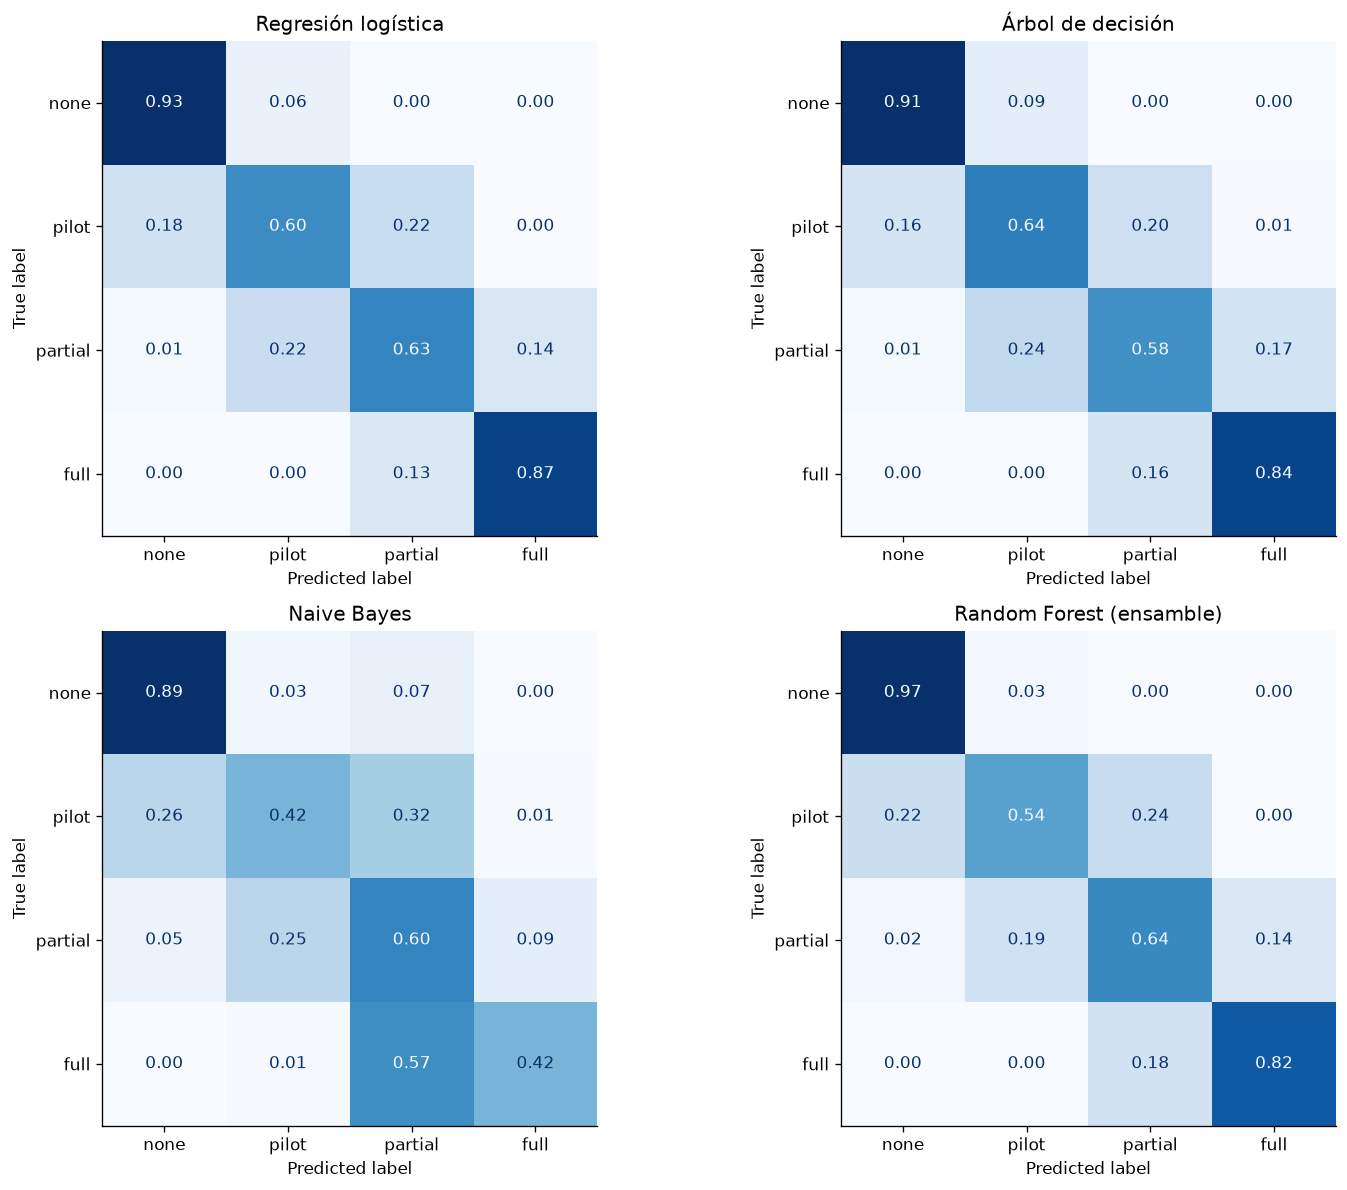

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (nombre, pred) in zip(axes.flat, predicciones_test.items()):
    cm = confusion_matrix(y_test, pred, labels=orden_etapas, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=orden_etapas).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False
    )
    ax.set_title(nombre)
plt.tight_layout()
plt.savefig(SALIDAS / "matrices_confusion_tp3.png", dpi=250, bbox_inches="tight")
plt.show()

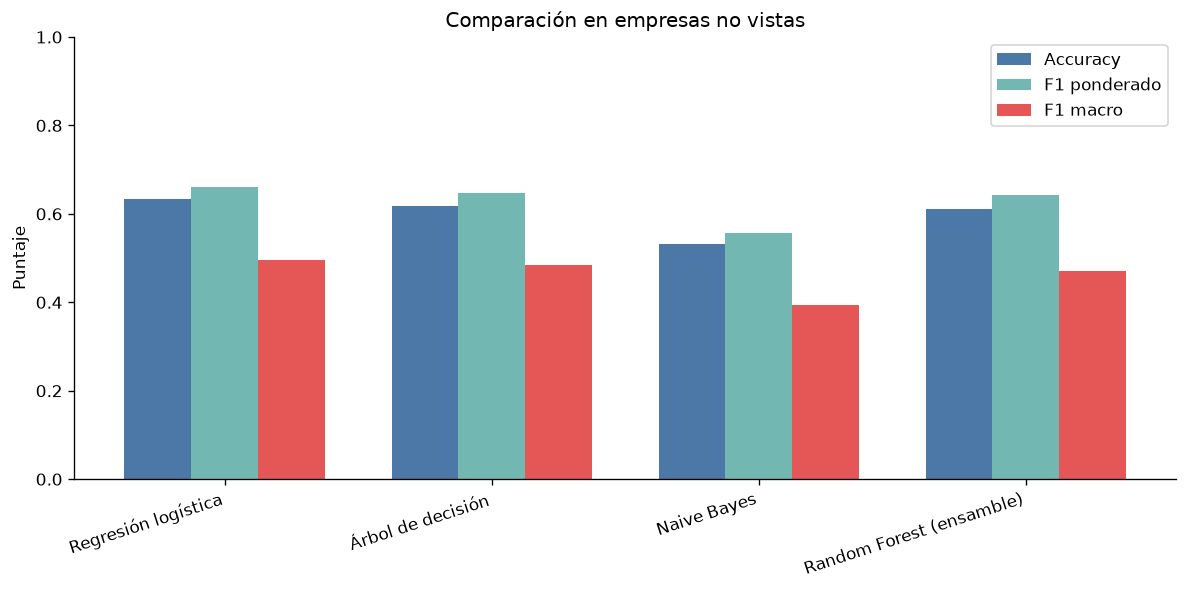

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_comparativa_tp3)); ancho = 0.25
ax.bar(x-ancho, df_comparativa_tp3["Accuracy (Test)"], ancho, label="Accuracy", color="#4C78A8")
ax.bar(x, df_comparativa_tp3["F1 ponderado (Test)"], ancho, label="F1 ponderado", color="#72B7B2")
ax.bar(x+ancho, df_comparativa_tp3["F1 macro (Test)"], ancho, label="F1 macro", color="#E45756")
ax.set_ylabel("Puntaje")
ax.set_title("Comparación en empresas no vistas")
ax.set_xticks(x, df_comparativa_tp3["Modelo"], rotation=18, ha="right")
ax.set_ylim(0, 1); ax.legend()
plt.tight_layout()
plt.savefig(SALIDAS / "comparativa_metricas_tp3.png", dpi=250, bbox_inches="tight")
plt.show()

,k,Inercia,Silueta,Davies-Bouldin
0,2,94693.5737,0.1699,2.0174
1,3,84785.0367,0.1397,2.1929
2,4,78836.2266,0.1224,2.1378
3,5,74911.9851,0.1178,2.0947
4,6,71724.6224,0.1100,2.0710


Se selecciona k=2 por la mayor silueta en la muestra de entrenamiento; el índice Davies-Bouldin complementa la lectura (menor es mejor).


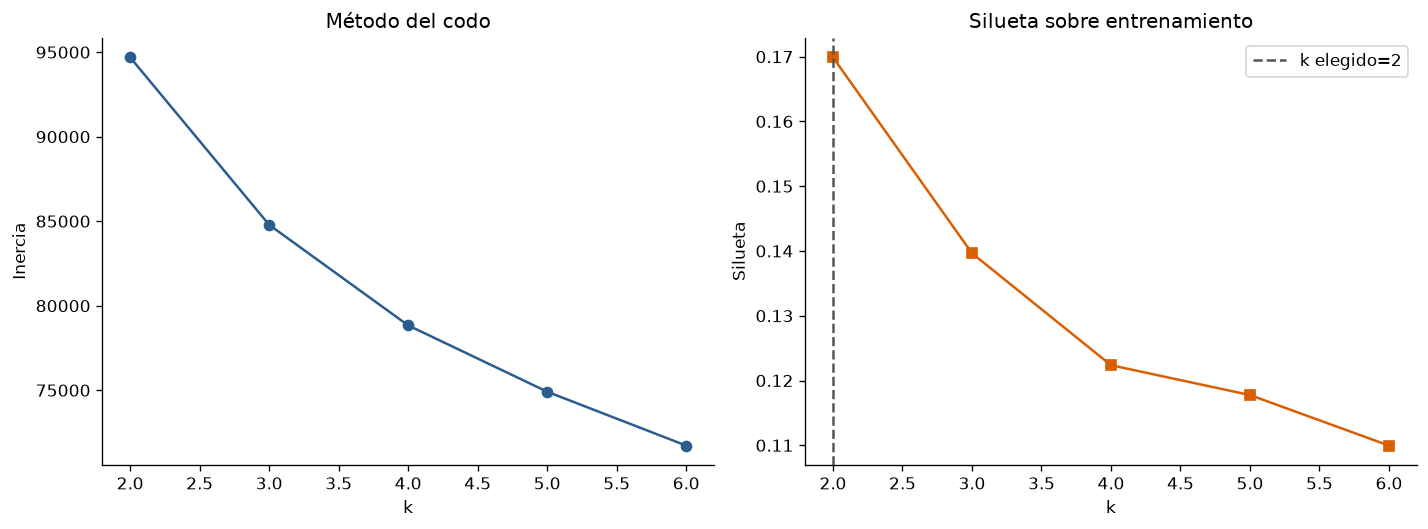

/Users/agus/Desktop/Facultad/CUARTO/Aprendizaje automatico/aa-2026-entorno/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:134: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/Users/agus/Desktop/Facultad/CUARTO/Aprendizaje automatico/aa-2026-entorno/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/agus/Desktop/Facultad/CUARTO/Aprendizaje automatico/aa-2026-entorno/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)
           ^^^^^^^^

In [10]:
# Clustering opcional. Se ajusta en TRAIN; el test se reserva para comparar después.
from sklearn.cluster import KMeans

preprocesador_cluster = crear_preprocesador().fit(X_train)
X_cluster_train = preprocesador_cluster.transform(X_train)
X_cluster_test = preprocesador_cluster.transform(X_test)

# Muestra reproducible del entrenamiento para seleccionar k sin mirar etiquetas.
rng = np.random.default_rng(SEMILLA)
n_cluster = min(15_000, len(X_cluster_train))
idx_cluster = rng.choice(len(X_cluster_train), size=n_cluster, replace=False)
X_cluster_muestra = X_cluster_train[idx_cluster]
rango_k = range(2, 7)
inercias, siluetas, davies_bouldin = [], [], []
for k in rango_k:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=5, max_iter=200)
    etiquetas = km.fit_predict(X_cluster_muestra)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_cluster_muestra, etiquetas, sample_size=min(5_000, len(etiquetas)), random_state=SEMILLA))
    davies_bouldin.append(davies_bouldin_score(X_cluster_muestra, etiquetas))

k_optimo = list(rango_k)[int(np.argmax(siluetas))]
metricas_k = pd.DataFrame({"k": list(rango_k), "Inercia": inercias, "Silueta": siluetas, "Davies-Bouldin": davies_bouldin})
display(metricas_k.round(4))
print(f"Se selecciona k={k_optimo} por la mayor silueta en la muestra de entrenamiento; el índice Davies-Bouldin complementa la lectura (menor es mejor).")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(list(rango_k), inercias, marker="o", color=COLOR_BASE)
ax1.set(title="Método del codo", xlabel="k", ylabel="Inercia")
ax2.plot(list(rango_k), siluetas, marker="s", color=COLOR_LINEA)
ax2.axvline(k_optimo, linestyle="--", color="#555", label=f"k elegido={k_optimo}")
ax2.set(title="Silueta sobre entrenamiento", xlabel="k", ylabel="Silueta")
ax2.legend()
plt.tight_layout()
plt.savefig(SALIDAS / "seleccion_kmeans_tp3.png", dpi=250, bbox_inches="tight")
plt.show()

In [11]:
# Ajustar K-Means con la muestra de entrenamiento y asignar clusters a test.
kmeans_final = KMeans(n_clusters=k_optimo, random_state=SEMILLA, n_init=10, max_iter=300)
kmeans_final.fit(X_cluster_muestra)
clusters_test = kmeans_final.predict(X_cluster_test)

df_cruce = pd.DataFrame({"Etapa real": y_test.astype(str).to_numpy(), "Cluster": [f"Cluster {c}" for c in clusters_test]})
tabla_contingencia = pd.crosstab(df_cruce["Etapa real"], df_cruce["Cluster"], normalize="index").reindex(orden_etapas).fillna(0)*100
display(tabla_contingencia.round(2))
tabla_contingencia.to_csv(SALIDAS / "contingencia_clustering_tp3.csv")

Cluster,Cluster 0,Cluster 1
Etapa real,,
none,3.55,96.45
pilot,19.91,80.09
partial,48.68,51.32
full,70.62,29.38


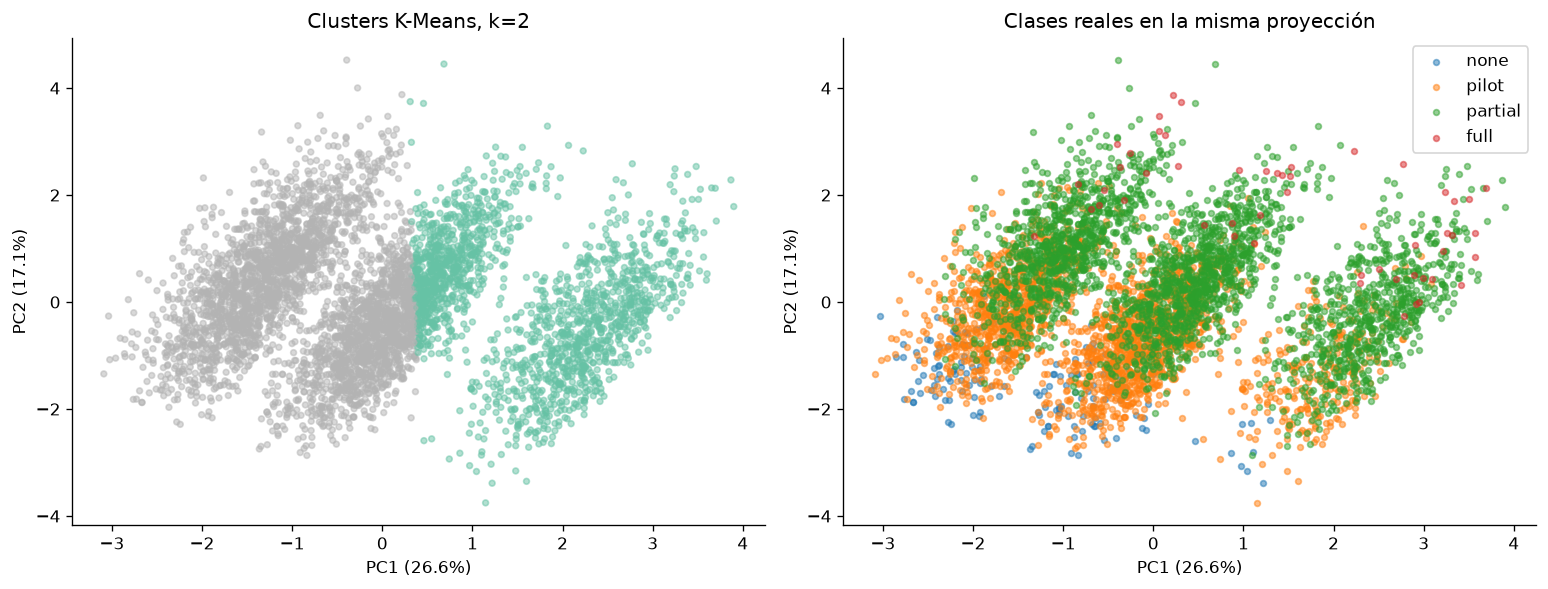

In [12]:
# Proyectar test sobre PCA ajustado con entrenamiento y colorear por cluster y clase conocida.
n_pca = min(5_000, len(X_cluster_test))
idx_pca = rng.choice(len(X_cluster_test), size=n_pca, replace=False)
pca = PCA(n_components=2, random_state=SEMILLA).fit(X_cluster_muestra)
X_pca = pca.transform(X_cluster_test[idx_pca])
y_sub_real = y_test.iloc[idx_pca].astype(str).to_numpy()
clusters_sub = clusters_test[idx_pca]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters_sub, cmap="Set2", alpha=.5, s=12)
ax1.set_title(f"Clusters K-Means, k={k_optimo}")
ax1.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax1.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
for etapa in orden_etapas:
    mask = y_sub_real == etapa
    ax2.scatter(X_pca[mask, 0], X_pca[mask, 1], label=etapa, alpha=.5, s=12)
ax2.set_title("Clases reales en la misma proyección")
ax2.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax2.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax2.legend()
plt.tight_layout()
plt.savefig(SALIDAS / "pca_clusters_vs_clases_tp3.png", dpi=250, bbox_inches="tight")
plt.show()

In [13]:
# Persistir el clasificador con mayor F1 macro y casos de prueba de empresas no vistas para Streamlit.
mejores = dict(modelos_clasif)
modelo_clasificacion_seleccionado = mejores[mejor_clasificador]
bundle_clasificacion = {
    "model": modelo_clasificacion_seleccionado,
    "features": predictores,
    "target": target_col,
    "model_name": mejor_clasificador,
    "labels": orden_etapas,
    "category_options": {
        "country": sorted(df["country"].dropna().astype(str).unique().tolist()),
        "industry": sorted(df["industry"].dropna().astype(str).unique().tolist()),
    },
}
joblib.dump(bundle_clasificacion, SALIDAS / "modelo_clasificacion_tp3.joblib")
filas_test = df.iloc[test_idx].copy()
demo_clas = (filas_test.groupby(target_col, observed=True, group_keys=False)
             .head(3).copy().reset_index(drop=True))
demo_clas.insert(0, "demo_id", [f"CLA-{i:02d}" for i in range(1, len(demo_clas)+1)])
demo_clas[["demo_id", "company_id", *predictores, target_col]].to_csv(
    SALIDAS / "muestras_prueba_clasificacion.csv", index=False
)
print(f"Guardado {mejor_clasificador} y {len(demo_clas)} muestras reservadas del test.")

Guardado Regresión logística y 12 muestras reservadas del test.


In [14]:
# Responder el cuestionario del TP3 con las métricas calculadas en esta ejecución.
from IPython.display import Markdown, display

m = df_comparativa_tp3.set_index("Modelo")
best = m.loc[mejor_clasificador]
rf = m.loc["Random Forest (ensamble)"]
log = m.loc["Regresión logística"]
rf_delta = rf["F1 macro (Test)"] - log["F1 macro (Test)"]
max_gap = m["Brecha F1 macro"].idxmax()
texto = f"""## Interpretación de resultados

1. **Modelo elegido y trade-off.** Con F1 macro como criterio principal, se elige **{mejor_clasificador}** (F1 macro de prueba {best['F1 macro (Test)']:.3f}; accuracy {best['Accuracy (Test)']:.3f}; recall macro {best['Recall macro (Test)']:.3f}). F1 macro pondera por igual las clases. Si la aplicación prioriza detectar una etapa minoritaria, hay que comparar su recall y falsos positivos en la matriz de confusión antes de privilegiar accuracy o precision.

2. **Ajuste y desbalance.** La mayor brecha de F1 macro entre entrenamiento y prueba corresponde a {max_gap} ({m.loc[max_gap, 'Brecha F1 macro']:.3f}). La tabla de distribución muestra las proporciones en ambos conjuntos; el split mantiene grupos empresariales separados y aproxima la estratificación. El uso de pesos balanceados en logística, árbol y Random Forest ayuda a que las clases raras pesen más, aunque puede bajar precision. GaussianNB no usa ese ponderado. Las métricas por clase y las matrices permiten ver ese intercambio.

3. **Ensamble y clustering.** Random Forest cambia el F1 macro en {rf_delta:+.3f} respecto de la logística; si la ganancia es pequeña o negativa, su mayor complejidad no se justifica solo por las métricas observadas. K-Means se ajustó sin las etiquetas en la muestra de entrenamiento. La contingencia y la proyección PCA muestran cuánto coinciden sus grupos con las etapas, pero los clusters no son equivalentes a clases y la coincidencia visual no demuestra causalidad.
"""
display(Markdown(texto))

## Interpretación de resultados

1. **Modelo elegido y trade-off.** Con F1 macro como criterio principal, se elige **Regresión logística** (F1 macro de prueba 0.495; accuracy 0.633; recall macro 0.759). F1 macro pondera por igual las clases. Si la aplicación prioriza detectar una etapa minoritaria, hay que comparar su recall y falsos positivos en la matriz de confusión antes de privilegiar accuracy o precision.

2. **Ajuste y desbalance.** La mayor brecha de F1 macro entre entrenamiento y prueba corresponde a Naive Bayes (0.015). La tabla de distribución muestra las proporciones en ambos conjuntos; el split mantiene grupos empresariales separados y aproxima la estratificación. El uso de pesos balanceados en logística, árbol y Random Forest ayuda a que las clases raras pesen más, aunque puede bajar precision. GaussianNB no usa ese ponderado. Las métricas por clase y las matrices permiten ver ese intercambio.

3. **Ensamble y clustering.** Random Forest cambia el F1 macro en -0.025 respecto de la logística; si la ganancia es pequeña o negativa, su mayor complejidad no se justifica solo por las métricas observadas. K-Means se ajustó sin las etiquetas en la muestra de entrenamiento. La contingencia y la proyección PCA muestran cuánto coinciden sus grupos con las etapas, pero los clusters no son equivalentes a clases y la coincidencia visual no demuestra causalidad.


## Limitaciones

La fuente no documenta cómo se generaron las observaciones. Además, la etapa objetivo se construye por tramos a partir de una tasa continua y las clases tienen tamaños distintos. El rendimiento describe este archivo y la separación de empresas empleada; no demuestra que las mismas tasas de error se mantengan en otra población. La selección final usa F1 macro, pero la elección puede variar si el costo de falsos negativos o falsos positivos cambia en la aplicación.